In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display

CSV_FOLDER = Path(r"C:\Users\koand\OneDrive\Documents\GitHub\DOPE-MURI\ORD_files\ORD_datasets_csv\ORD_datasets_csv")

pd.set_option("display.max_columns", None, "display.max_colwidth", 80)

for path in sorted(CSV_FOLDER.glob("*.csv")):
    df = pd.read_csv(path, low_memory=False)
    print(f"\n=== {path.name}  ({len(df):,} rows x {df.shape[1]:,} columns)")
    display(df.iloc[[1]])                     # the row at index 1
    display(df.describe(include="all").T)     # statistics, one row per column


These 19 columns are the same for each  
dataset_id, dataset_name, reaction_id, reactant_names, reactant_smiles, reagent_names, reagent_smiles, catalyst_names, catalyst_smiles, solvent_names, solvent_smiles, temperature, temperature_unit, primary_reaction_time, primary_reaction_time_unit, primary_product_smiles, primary_yield_percent, primary_yield_analysis, publication_doi

There are 17 additional source files

In [ ]:
from pathlib import Path
import json
import re
import time

import pandas as pd
import requests
from IPython.display import display
from rdkit import Chem, RDLogger

RDLogger.DisableLog("rdApp.*")
pd.set_option("display.max_columns", None, "display.max_colwidth", 80, "display.width", 250)

CSV_FOLDER = Path(r"C:\Users\koand\OneDrive\Documents\GitHub\DOPE-MURI\ORD_files\ORD_datasets_csv\ORD_datasets_csv")
# CSV_FILE = CSV_FOLDER / "Newman-Stonebraker_3b_Suzuki_Ni-ligand-screens.csv"
CSV_FILE = CSV_FOLDER / "Newman-Stonebraker_3b_Suzuki_Ni-ligand-screens.csv"


# A component counts as "the ligand" when its SMILES has a phosphorus bonded to
# carbon (phosphines; not phosphate bases) and its role is not one of these.
NOT_LIGAND_ROLES = {"REACTANT", "PRODUCT", "SOLVENT"}
# Or name the inputs that hold the ligand yourself, e.g. ["Ligand in Solvent"].
# Leave empty to detect automatically.
LIGAND_INPUTS = []

INCLUDE_AMOUNTS = True        # a different loading of a non-ligand component -> a different group
MIN_LIGANDS = 2               # only print groups that compare at least this many ligands
LOOKUP_NAMES_ONLINE = True    # SMILES without a recorded name -> PubChem name
NAME_CACHE = CSV_FOLDER / "_smiles_names_cache.json"


In [8]:
COMPONENT_COLUMN = re.compile(r"^source\.inputs\.(?P<input>.+?)\.components\[(?P<comp>\d+)\]\.(?P<field>.+)$")


def components_table(df):
    """One row per (reaction, component): input, role, name, smiles, amount."""
    fields = {}
    for column in df.columns:
        match = COMPONENT_COLUMN.match(column)
        if match:
            key = (match["input"], int(match["comp"]))
            fields.setdefault(key, {})[match["field"]] = column

    parts = []
    for (input_name, comp), cols in fields.items():
        part = pd.DataFrame({"row": df.index, "input": input_name, "component": comp})
        part["role"] = df[cols["reaction_role"]].values if "reaction_role" in cols else ""
        part["name"], part["smiles"] = pd.NA, pd.NA
        k = 1
        while f"identifiers[{k}].type" in cols:
            kind = df[cols[f"identifiers[{k}].type"]]
            value = df[cols[f"identifiers[{k}].value"]]
            for target, wanted in (("name", "NAME"), ("smiles", "SMILES")):
                fill = part[target].isna().to_numpy() & (kind == wanted).to_numpy()
                part.loc[fill, target] = value.to_numpy()[fill]
            k += 1
        amount = pd.Series("", index=df.index)
        for quantity in ("moles", "mass", "volume"):
            v, u = cols.get(f"amount.{quantity}.value"), cols.get(f"amount.{quantity}.units")
            if v and u:
                has = df[v].notna()
                amount[has] = df.loc[has, v].round(6).astype(str) + " " + df.loc[has, u].astype(str)
        part["amount"] = amount.to_numpy()
        parts.append(part)

    comps = pd.concat(parts, ignore_index=True)
    # A component slot that this reaction does not use has no identifiers.
    comps = comps[comps["name"].notna() | comps["smiles"].notna()].reset_index(drop=True)
    comps["role"] = comps["role"].fillna("")
    comps["identity"] = comps["smiles"].fillna(comps["name"])
    return comps


In [9]:
_phosphine_cache = {}


def has_carbon_phosphorus(smiles):
    if not isinstance(smiles, str):
        return False
    if smiles not in _phosphine_cache:
        mol = Chem.MolFromSmiles(smiles)
        _phosphine_cache[smiles] = mol is not None and any(
            atom.GetSymbol() == "P" and any(n.GetSymbol() == "C" for n in atom.GetNeighbors())
            for atom in mol.GetAtoms())
    return _phosphine_cache[smiles]


def mark_ligands(comps):
    if LIGAND_INPUTS:
        comps["is_ligand"] = comps["input"].isin(LIGAND_INPUTS)
    else:
        comps["is_ligand"] = (~comps["role"].isin(NOT_LIGAND_ROLES)
                              & comps["smiles"].map(has_carbon_phosphorus))
    return comps


In [10]:
try:
    _names = json.loads(NAME_CACHE.read_text(encoding="utf-8"))
except (OSError, ValueError):
    _names = {}


def smiles_to_name(smiles):
    if smiles in _names:
        return _names[smiles]
    name = None
    if LOOKUP_NAMES_ONLINE:
        try:
            response = requests.post(
                "https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/smiles/property/Title,IUPACName/JSON",
                data={"smiles": smiles}, timeout=15)
            if response.ok:
                props = response.json()["PropertyTable"]["Properties"][0]
                name = props.get("Title") or props.get("IUPACName")
            time.sleep(0.25)   # PubChem asks for at most 5 requests per second
        except (requests.RequestException, KeyError, IndexError, ValueError):
            pass
    _names[smiles] = name or smiles
    try:
        NAME_CACHE.write_text(json.dumps(_names, indent=1), encoding="utf-8")
    except OSError:
        pass
    return _names[smiles]


def display_name(name, smiles):
    if isinstance(name, str) and name.strip():
        return name.strip()
    return smiles_to_name(smiles) if isinstance(smiles, str) else "?"


In [11]:
def condition_columns(df):
    """Reaction-level settings: conditions, setup, and the (first) reaction time."""
    return [c for c in df.columns
            if c.startswith(("source.conditions.", "source.setup."))
            or c.startswith("source.outcomes[1].reaction_time.")]


def split_by_ligand(df):
    comps = mark_ligands(components_table(df))
    fixed = comps[~comps["is_ligand"]]

    # Everything that is not the ligand, as one hashable key per reaction.
    fields = ["role", "identity"] + (["amount"] if INCLUDE_AMOUNTS else [])
    component_key = (fixed.assign(item=fixed[fields].astype(str).agg(" | ".join, axis=1))
                     .groupby("row")["item"].agg(lambda items: tuple(sorted(items))))
    conditions = condition_columns(df)
    condition_key = df[conditions].astype(str).agg(tuple, axis=1) if conditions else pd.Series("", index=df.index)
    key = pd.Series(list(zip(component_key.reindex(df.index), condition_key)), index=df.index)

    ligand = (comps[comps["is_ligand"]].groupby("row")
              .agg(ligand_name=("name", lambda s: "; ".join(s.dropna().astype(str))),
                   ligand_smiles=("smiles", lambda s: "; ".join(s.dropna().astype(str)))))
    df = df.join(ligand)
    # One label per reaction: the ligand's name, else its SMILES, else "(none)".
    df["ligand"] = (df["ligand_name"].where(df["ligand_name"].fillna("") != "", df["ligand_smiles"])
                    .fillna("(none)"))

    groups = {}
    for number, (_, rows) in enumerate(df.groupby(key, sort=False).groups.items(), 1):
        groups[number] = df.loc[rows]
    return groups, comps


In [14]:
df = pd.read_csv(CSV_FILE, low_memory=False)
groups, comps = split_by_ligand(df)

if not comps["is_ligand"].any():
    print("No ligand detected: set LIGAND_INPUTS by hand. Groups below are just unique conditions.")

shown = {n: g for n, g in groups.items() if g["ligand"].nunique() >= MIN_LIGANDS}
print(f"{CSV_FILE.name}: {len(df)} reactions -> {len(groups)} groups, "
      f"{len(shown)} with at least {MIN_LIGANDS} ligands (printed below)")

summary = []
for number, group in shown.items():
    rows = comps[comps["row"].isin(group.index) & ~comps["is_ligand"]]
    fixed = rows.drop_duplicates(["role", "identity"])
    reactants = [display_name(r.name, r.smiles) for r in fixed[fixed["role"] == "REACTANT"].itertuples()]
    others = [f"{display_name(r.name, r.smiles)} ({r.role.lower()})"
              for r in fixed[fixed["role"] != "REACTANT"].itertuples()]
    time_value = group["primary_reaction_time"].iloc[0]
    time_unit = group["primary_reaction_time_unit"].iloc[0]

    print(f"\n=== Group {number}: {len(group)} reactions, {group['ligand'].nunique()} ligands")
    print("  Reactants: " + "  +  ".join(reactants))
    print("  Also:      " + ", ".join(others))
    print(f"  Conditions: {group['temperature'].iloc[0]} {group['temperature_unit'].iloc[0]}, "
          f"{time_value} {time_unit}")
    #display(group[["ligand", "ligand_smiles", "primary_yield_percent"]].head())
    summary.append({"group": number, "reactions": len(group), "ligands": group["ligand"].nunique(),
                    "reactants": " + ".join(reactants), "time": f"{time_value} {time_unit}",
                    "mean_yield": group["primary_yield_percent"].mean()})

summary = pd.DataFrame(summary).set_index("group")
display(summary)


Newman-Stonebraker_3b_Suzuki_Ni-ligand-screens.csv: 450 reactions -> 5 groups, 5 with at least 2 ligands (printed below)

=== Group 1: 90 reactions, 90 ligands
  Reactants: 4-Chloroanisole  +  4-(Trifluoromethyl)phenylboronic acid
  Also:      K3PO4 (reagent), dioxane (solvent), Ni(cod)2 (catalyst), water (reagent)
  Conditions: 60.0 CELSIUS, 2.0 HOUR

=== Group 2: 90 reactions, 90 ligands
  Reactants: 4-Chloroanisole  +  2,4,6-Trimethylbenzeneboronic acid
  Also:      K3PO4 (reagent), dioxane (solvent), Ni(cod)2 (catalyst), water (reagent)
  Conditions: 60.0 CELSIUS, 18.0 HOUR

=== Group 3: 90 reactions, 90 ligands
  Reactants: 4-Chloroanisole  +  4-Ethoxycarbonylphenylboronic acid
  Also:      K3PO4 (reagent), dioxane (solvent), Ni(cod)2 (catalyst), water (reagent)
  Conditions: 60.0 CELSIUS, 2.0 HOUR

=== Group 4: 90 reactions, 90 ligands
  Reactants: 1-Chloro-4-(trifluoromethyl)benzene  +  (4-Methoxyphenyl)boronic acid
  Also:      K3PO4 (reagent), dioxane (solvent), Ni(cod)2 (cata

,reactions,ligands,reactants,time,mean_yield
group,,,,,
1,90,90,4-Chloroanisole + 4-(Trifluoromethyl)phenylboronic acid,2.0 HOUR,20.144444
2,90,90,"4-Chloroanisole + 2,4,6-Trimethylbenzeneboronic acid",18.0 HOUR,9.733333
3,90,90,4-Chloroanisole + 4-Ethoxycarbonylphenylboronic acid,2.0 HOUR,9.555556
4,90,90,1-Chloro-4-(trifluoromethyl)benzene + (4-Methoxyphenyl)boronic acid,0.75 HOUR,36.966667
5,90,90,4-Chloroanisole + Phenylboronic Acid,2.0 HOUR,15.155556



=== Group 1: 90 reactions, 90 ligands


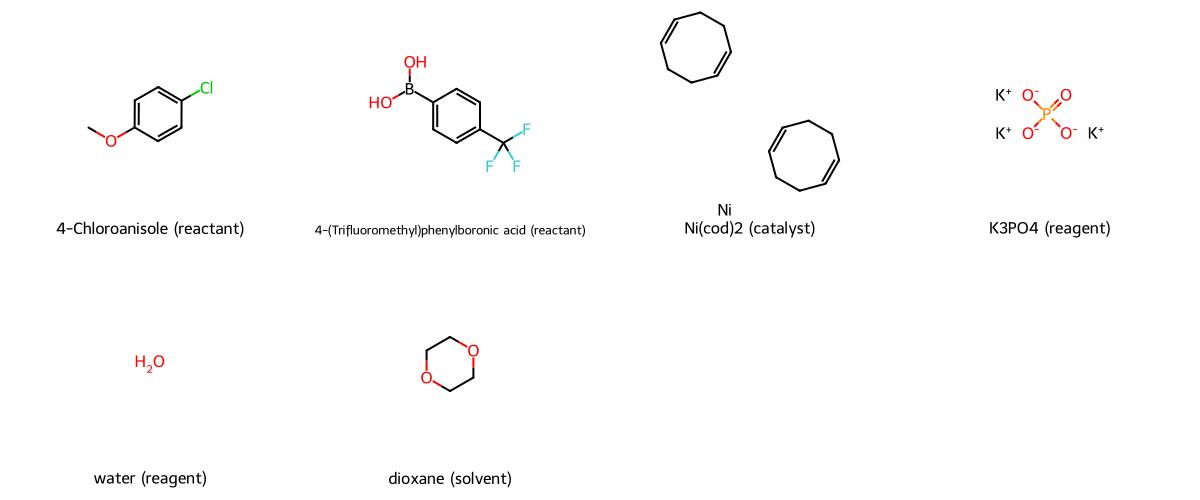


=== Group 2: 90 reactions, 90 ligands


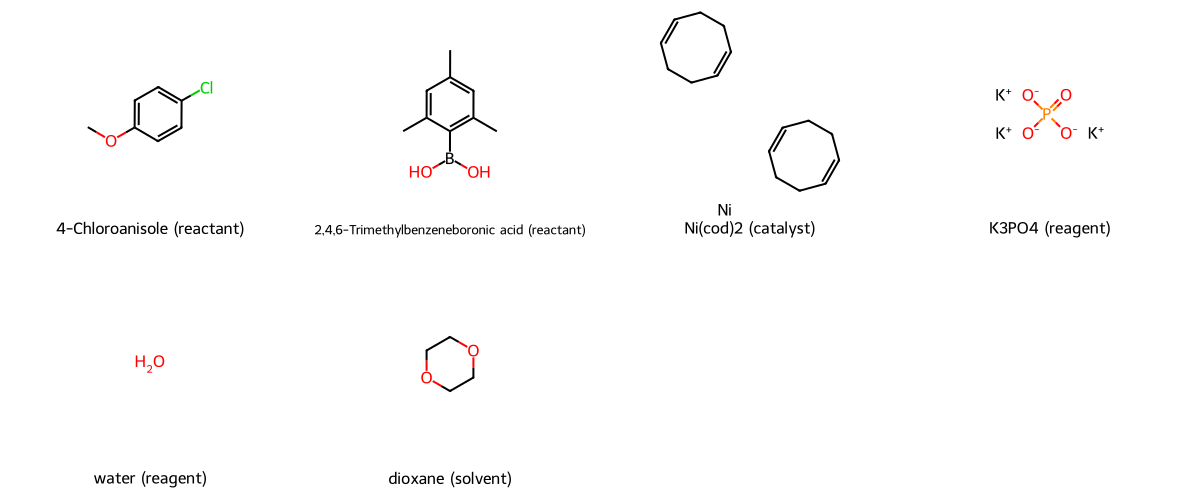


=== Group 3: 90 reactions, 90 ligands


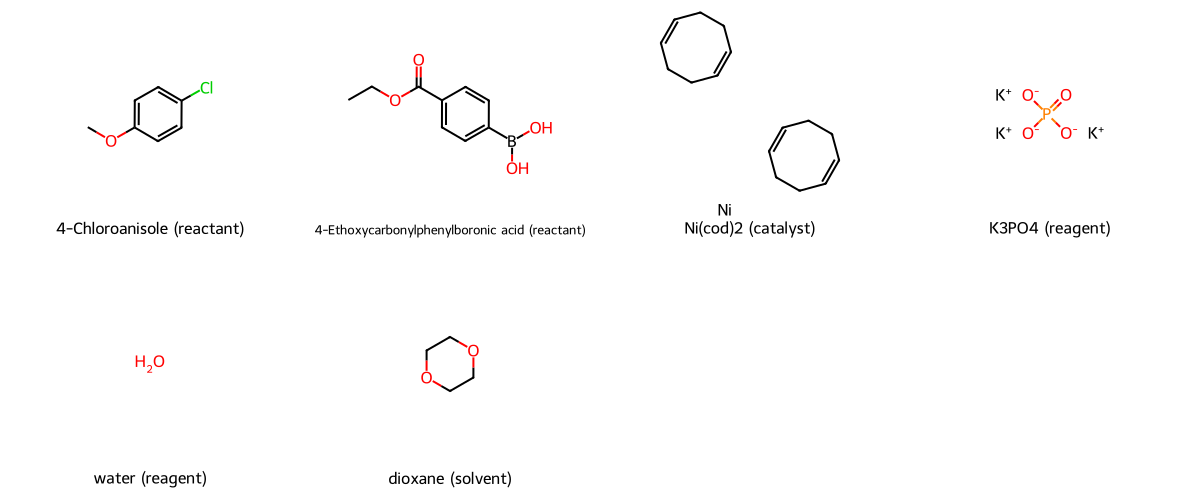


=== Group 4: 90 reactions, 90 ligands


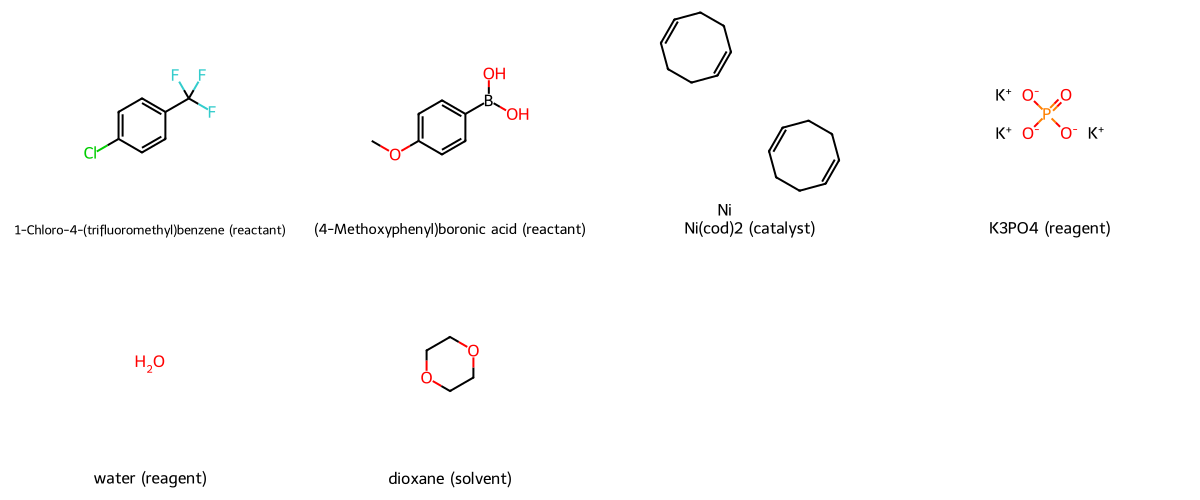


=== Group 5: 90 reactions, 90 ligands


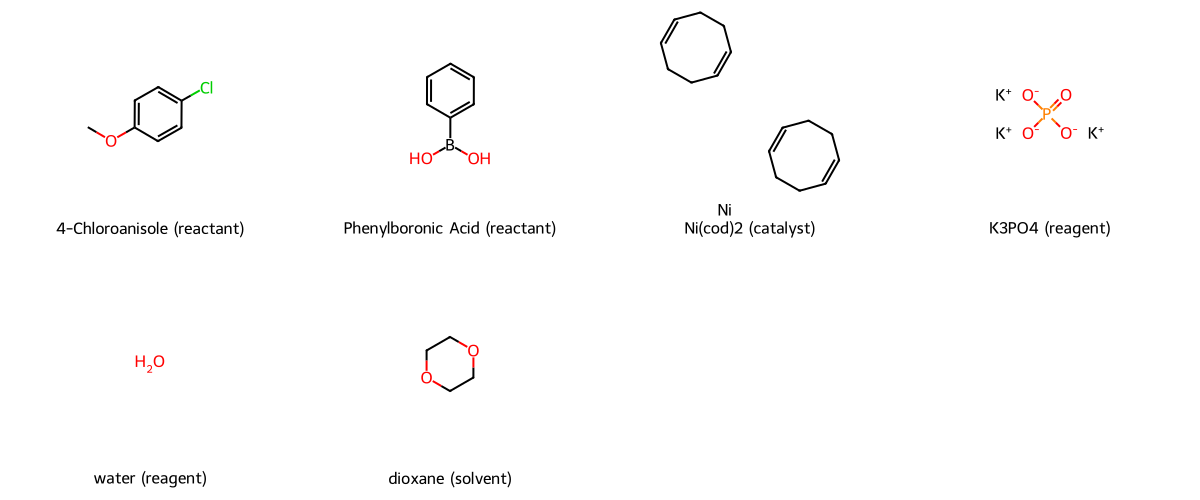

In [13]:
from IPython.display import Image
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D

# ---- Editable ----
PER_ROW = 4
PANEL_W, PANEL_H = 300, 250        # pixels per structure
LEGEND_FONT = 16
SKIP_ROLES = set()                 # e.g. {"SOLVENT", "INTERNAL_STANDARD"} to leave those out
MAX_GROUPS_TO_DRAW = 20            # HiTEA has thousands of groups
# ------------------

rdDepictor.SetPreferCoordGen(True)     # cleaner ring layouts


def draw_components(rows):
    """One grid image of the given components, each labelled 'name (role)'."""
    mols, legends, undrawn = [], [], []
    for r in rows.itertuples():
        label = f"{display_name(r.name, r.smiles)} ({r.role.lower() or 'no role'})"
        mol = Chem.MolFromSmiles(r.smiles) if isinstance(r.smiles, str) else None
        if mol is None:
            undrawn.append(label)
            continue
        rdDepictor.Compute2DCoords(mol)
        mols.append(mol)
        legends.append(label)
    if mols:
        n_rows = -(-len(mols) // PER_ROW)
        drawer = rdMolDraw2D.MolDraw2DCairo(PANEL_W * min(PER_ROW, len(mols)), PANEL_H * n_rows,
                                            PANEL_W, PANEL_H)
        drawer.drawOptions().legendFontSize = LEGEND_FONT
        drawer.DrawMolecules(mols, legends=legends)
        drawer.FinishDrawing()
        display(Image(drawer.GetDrawingText()))
    if undrawn:
        print("  No drawable SMILES for: " + ", ".join(undrawn))


for number, group in list(shown.items())[:MAX_GROUPS_TO_DRAW]:
    rows = comps[comps["row"].isin(group.index) & ~comps["is_ligand"] & ~comps["role"].isin(SKIP_ROLES)]
    # Reactants first, then the rest by role; each compound once.
    rows = (rows.drop_duplicates(["role", "identity"])
                .assign(order=lambda d: (d["role"] != "REACTANT").astype(int))
                .sort_values(["order", "role"]))
    print(f"\n=== Group {number}: {len(group)} reactions, {group['ligand'].nunique()} ligands")
    draw_components(rows)

if len(shown) > MAX_GROUPS_TO_DRAW:
    print(f"\n{len(shown) - MAX_GROUPS_TO_DRAW} more groups not drawn; raise MAX_GROUPS_TO_DRAW to see them.")
